In [97]:
import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from torch.distributions.uniform import Uniform
from torch.optim import Adam
from torch.utils.data import TensorDataset, DataLoader

In [98]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)  # subtract the max so exp() never overflows
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

In [99]:
inputs = torch.tensor([
    [1., 0., 0., 0.],
    [0., 1., 0., 0.],
    [0., 0., 1., 0.],
    [0., 0., 0., 1.],
])

labels = torch.tensor([
    [0., 1., 0., 0.],
    [0., 0., 1., 0.],
    [0., 0., 0., 1.],
    [0., 1., 0., 0.],
])

dataset = TensorDataset(inputs, labels)
dataloader = DataLoader(dataset)

In [100]:
class WordEmbeddingFromScratch(L.LightningModule):

    def __init__(self):
        super().__init__()

        min_value = -0.5
        max_value = 0.5

        self.input1_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input1_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input2_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input2_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input3_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input3_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input4_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.input4_w2 = nn.Parameter(Uniform(min_value, max_value).sample())

        self.output1_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output1_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output2_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output2_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output3_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output3_w2 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output4_w1 = nn.Parameter(Uniform(min_value, max_value).sample())
        self.output4_w2 = nn.Parameter(Uniform(min_value, max_value).sample())

        self.loss = nn.CrossEntropyLoss()

    def forward(self, input):
        input = input[0]

        inputs_to_top_hidden = (
                (input[0] * self.input1_w1) +
                (input[1] * self.input2_w1) +
                (input[2] * self.input3_w1) +
                (input[3] * self.input4_w1)
        )

        inputs_to_bottom_hidden = (
                (input[0] * self.input1_w2) +
                (input[1] * self.input2_w2) +
                (input[2] * self.input3_w2) +
                (input[3] * self.input4_w2)
        )

        output1 = (
                inputs_to_top_hidden * self.output1_w1
                + inputs_to_bottom_hidden * self.output1_w2
        )
        output2 = (
                inputs_to_top_hidden * self.output2_w1
                + inputs_to_bottom_hidden * self.output2_w2
        )
        output3 = (
                inputs_to_top_hidden * self.output3_w1
                + inputs_to_bottom_hidden * self.output3_w2
        )
        output4 = (
                inputs_to_top_hidden * self.output4_w1
                + inputs_to_bottom_hidden * self.output4_w2
        )

        output_presoftmax = torch.stack([output1, output2, output3, output4])

        return output_presoftmax

    def configure_optimizers(self):
        return Adam(self.parameters(), lr=0.1)

    def training_step(self, batch, bach_idx):
        input_i, label_i = batch
        output_i = self.forward(input_i)
        loss = self.loss(output_i, label_i[0])

        return loss

In [101]:
modelFromScratch = WordEmbeddingFromScratch()

print("Before optimization, the parameters are...")
for name, param in modelFromScratch.named_parameters():
    print(name, param.data)

Before optimization, the parameters are...
input1_w1 tensor(0.2577)
input1_w2 tensor(0.2170)
input2_w1 tensor(-0.0500)
input2_w2 tensor(0.2751)
input3_w1 tensor(0.2183)
input3_w2 tensor(-0.0562)
input4_w1 tensor(0.4824)
input4_w2 tensor(0.1490)
output1_w1 tensor(-0.0108)
output1_w2 tensor(-0.3243)
output2_w1 tensor(-0.4312)
output2_w2 tensor(0.0611)
output3_w1 tensor(0.4581)
output3_w2 tensor(-0.1105)
output4_w1 tensor(-0.1634)
output4_w2 tensor(0.3127)


In [102]:
data = {
    "w1": [
        modelFromScratch.input1_w1.item(),
        modelFromScratch.input2_w1.item(),
        modelFromScratch.input3_w1.item(),
        modelFromScratch.input4_w1.item(),
    ],
    "w2": [
        modelFromScratch.input1_w2.item(),
        modelFromScratch.input2_w2.item(),
        modelFromScratch.input3_w2.item(),
        modelFromScratch.input4_w2.item(),
    ],
    "token": ["Troll2", "is", "great", "Gymkata"],
    "input": ["input1", "input2", "input3", "input4"],
}

df = pd.DataFrame(data)
df

,w1,w2,token,input
0,0.257712,0.217030,Troll2,input1
1,-0.050007,0.275122,is,input2
2,0.218286,-0.056200,great,input3
3,0.482390,0.149027,Gymkata,input4


Text(0.48238956928253174, 0.1490270495414734, 'Gymkata')

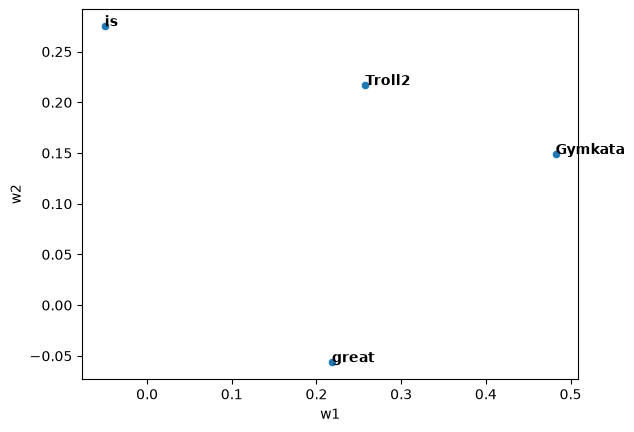

In [103]:
sns.scatterplot(data=df, x="w1", y="w2")
plt.text(df.w1[0], df.w2[0], df.token[0],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[1], df.w2[1], df.token[1],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[2], df.w2[2], df.token[2],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[3], df.w2[3], df.token[3],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

In [104]:
trainer = L.Trainer(max_epochs=100)
trainer.fit(modelFromScratch, train_dataloaders=dataloader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name         | Type             | Params | Mode  | FLOPs
------------------------------------------------------------------
0 | loss         | CrossEntropyLoss | 0      | train | 0    
  | other params | n/a              | 16     | n/a   | n/a  
------------------------------------------------------------------
16        Trainable params
0         Non-trainable params
16        Total params
0.000     Total estimated model params size (MB)
1         Modules in train mode
0         

Epoch 99: 100%|██████████| 4/4 [00:00<00:00, 61.31it/s, v_num=31] 

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 4/4 [00:00<00:00, 37.77it/s, v_num=31]


In [105]:
data = {
    "w1": [
        modelFromScratch.input1_w1.item(),
        modelFromScratch.input2_w1.item(),
        modelFromScratch.input3_w1.item(),
        modelFromScratch.input4_w1.item(),
    ],
    "w2": [
        modelFromScratch.input1_w2.item(),
        modelFromScratch.input2_w2.item(),
        modelFromScratch.input3_w2.item(),
        modelFromScratch.input4_w2.item(),
    ],
    "token": ["Troll2", "is", "great", "Gymkata"],
    "input": ["input1", "input2", "input3", "input4"],
}

df = pd.DataFrame(data)
df

,w1,w2,token,input
0,0.544065,2.147881,Troll2,input1
1,2.405841,-1.656415,is,input2
2,-2.847980,0.055489,great,input3
3,1.273608,1.997809,Gymkata,input4


Text(1.273607611656189, 1.997808814048767, 'Gymkata')

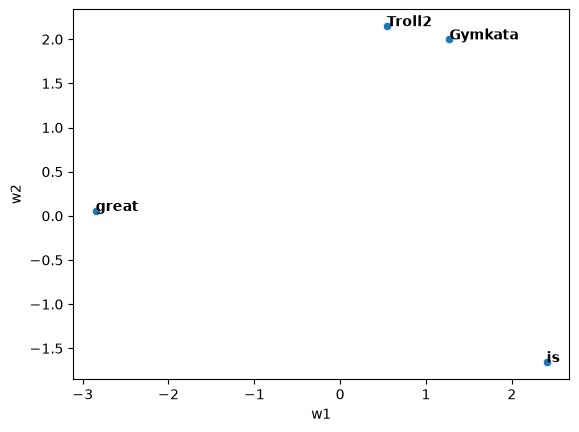

In [106]:
sns.scatterplot(data=df, x="w1", y="w2")
plt.text(df.w1[0], df.w2[0], df.token[0],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[1], df.w2[1], df.token[1],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[2], df.w2[2], df.token[2],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[3], df.w2[3], df.token[3],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

In [107]:
softmax = nn.Softmax(dim=0)
print(torch.round(softmax(modelFromScratch(torch.tensor([[1., 0., 0., 0, ]])))))
print(torch.round(softmax(modelFromScratch(torch.tensor([[0., 1., 0., 0, ]])))))
print(torch.round(softmax(modelFromScratch(torch.tensor([[0., 0., 1., 0, ]])))))
print(torch.round(softmax(modelFromScratch(torch.tensor([[0., 0., 0., 1.]])))))

tensor([0., 1., 0., 0.], grad_fn=<RoundBackward0>)
tensor([0., 0., 1., 0.], grad_fn=<RoundBackward0>)
tensor([0., 0., 0., 1.], grad_fn=<RoundBackward0>)
tensor([0., 1., 0., 0.], grad_fn=<RoundBackward0>)


In [108]:
class WordEmbeddingWithLinear(L.LightningModule):
    def __init__(self):
        super().__init__()

        self.input_to_hidden = nn.Linear(in_features=4, out_features=2, bias=False)
        self.hidden_to_output = nn.Linear(in_features=2, out_features=4, bias=False)

        self.loss = nn.CrossEntropyLoss()

    def forward(self, input):
        hidden = self.input_to_hidden(input)
        output_values = self.hidden_to_output(hidden)
        return output_values

    def configure_optimizers(self):
        return Adam(self.parameters(), lr=0.1)

    def training_step(self, batch, bach_idx):
        input_i, label_i = batch
        output_i = self.forward(input_i)
        loss = self.loss(output_i, label_i)

        return loss

In [109]:
modelLinear = WordEmbeddingWithLinear()

data = {
    "w1": modelLinear.input_to_hidden.weight.detach()[0].numpy(),
    "w2": modelLinear.input_to_hidden.weight.detach()[1].numpy(),
    "token": ["Troll2", "is", "great", "Gymkata"],
    "input": ["input1", "input2", "input3", "input4"],
}

df = pd.DataFrame(data)
df

,w1,w2,token,input
0,0.470478,0.442877,Troll2,input1
1,-0.144948,-0.003512,is,input2
2,-0.078802,-0.381253,great,input3
3,0.350705,-0.186435,Gymkata,input4


Text(0.3507046699523926, -0.1864350438117981, 'Gymkata')

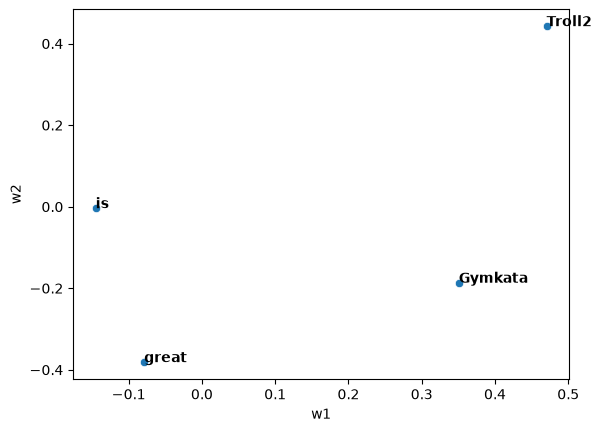

In [110]:
sns.scatterplot(data=df, x="w1", y="w2")
plt.text(df.w1[0], df.w2[0], df.token[0],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[1], df.w2[1], df.token[1],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[2], df.w2[2], df.token[2],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[3], df.w2[3], df.token[3],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

In [111]:
trainer = L.Trainer(max_epochs=100)
trainer.fit(modelLinear, train_dataloaders=dataloader)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name             | Type             | Params | Mode  | FLOPs
----------------------------------------------------------------------
0 | input_to_hidden  | Linear           | 8      | train | 0    
1 | hidden_to_output | Linear           | 8      | train | 0    
2 | loss             | CrossEntropyLoss | 0      | train | 0    
----------------------------------------------------------------------
16        Trainable params
0         Non-trainable params
16        Total params
0.000 

Epoch 99: 100%|██████████| 4/4 [00:00<00:00, 57.75it/s, v_num=32] 

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 4/4 [00:00<00:00, 43.05it/s, v_num=32]


Text(2.0518667697906494, -1.3125848770141602, 'Gymkata')

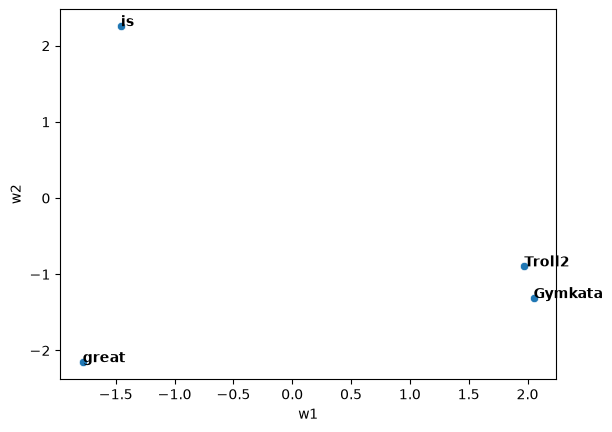

In [112]:
data = {
    "w1": modelLinear.input_to_hidden.weight.detach()[0].numpy(),
    "w2": modelLinear.input_to_hidden.weight.detach()[1].numpy(),
    "token": ["Troll2", "is", "great", "Gymkata"],
    "input": ["input1", "input2", "input3", "input4"],
}

df = pd.DataFrame(data)

sns.scatterplot(data=df, x="w1", y="w2")
plt.text(df.w1[0], df.w2[0], df.token[0],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[1], df.w2[1], df.token[1],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[2], df.w2[2], df.token[2],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

plt.text(df.w1[3], df.w2[3], df.token[3],
         horizontalalignment='left',
         size='medium',
         color='black',
         weight='semibold')

In [116]:
word_embeddings = nn.Embedding.from_pretrained(modelLinear.input_to_hidden.weight.T)
word_embeddings.weight

Parameter containing:
tensor([[ 1.9727, -0.8966],
        [-1.4562,  2.2563],
        [-1.7805, -2.1535],
        [ 2.0519, -1.3126]])

In [118]:
vocab = {'Troll2': 0,
         'is': 1,
         'great': 2,
         'Gymkata': 3}

word_embeddings(torch.tensor(vocab['great']))

tensor([-1.7805, -2.1535])